# Week 5 Part B ? The five decisions, computed

Every answer below is produced by executable code rather than opinion. The notebook uses the Week 5 files in this folder and states the numerical choices made for each figure.


In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler, quantile_transform

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', context='notebook')
except ImportError:
    plt.style.use('seaborn-v0_8-whitegrid')

BASE = Path.cwd()
if not (BASE / 'health_indicators.csv').exists() and (BASE / 'Week5').exists(): BASE = BASE / 'Week5'
health = pd.read_csv(BASE / 'health_indicators.csv')
dense = pd.read_csv(BASE / 'scatter_dense.csv')
small = pd.read_csv(BASE / 'smallarea_cases.csv')
with open(BASE / 'districts.geojson', encoding='utf-8') as f: geo = json.load(f)
features = geo['features']
num_cols = ['gdp_pc','healthcare_access','urban_pct','median_age','pop_m']
print('Data directory:', BASE)
print('health rows:', len(health), '| dense points:', len(dense), '| small-area units:', len(small))


Data directory: d:\University\ML Lab\Week5
health rows: 60 | dense points: 9000 | small-area units: 40


## 1. The size range

The population channel uses `matplotlib.scatter(s=...)`, where `s` is marker **area in points?**, not radius. I choose `sizes=(20, 900)` points?: 20 is a small but visible mark in the notebook figures, while 900 avoids allowing the largest countries to swallow nearby marks.


Chosen sizes=(lo, hi): (20.0, 900.0) points?
Smallest mark: 20.0 points? ? readable minimum
Largest mark: 900.0 points? ? bounded to avoid swallowing neighbours
Area ratio: 45.0 | diameter ratio sqrt(area ratio): 6.708
Area?not radius?check: plotted s values are areas; radius-equivalent ratio would be 6.708 while area ratio is 45.0


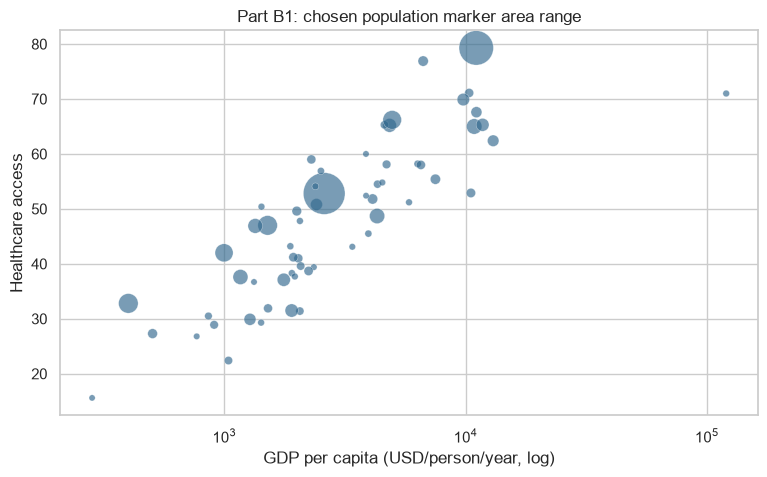

In [2]:
lo, hi = 20.0, 900.0
pop_min, pop_max = health.pop_m.min(), health.pop_m.max()
# Area is interpolated from population; this is deliberately not a radius interpolation.
areas = lo + (health.pop_m-pop_min)/(pop_max-pop_min)*(hi-lo)
diameter_ratio = math.sqrt(hi/lo)
print('Chosen sizes=(lo, hi):', (lo, hi), 'points?')
print('Smallest mark:', lo, 'points? ? readable minimum')
print('Largest mark:', hi, 'points? ? bounded to avoid swallowing neighbours')
print('Area ratio:', round(hi/lo, 2), '| diameter ratio sqrt(area ratio):', round(diameter_ratio, 3))
print('Area?not radius?check: plotted s values are areas; radius-equivalent ratio would be', round(diameter_ratio,3), 'while area ratio is', round(hi/lo,2))
fig, ax = plt.subplots(figsize=(9,5)); ax.scatter(health.gdp_pc, health.healthcare_access, s=areas, alpha=.65, color='#31688e', edgecolor='white', linewidth=.3)
ax.set_xscale('log'); ax.set(xlabel='GDP per capita (USD/person/year, log)', ylabel='Healthcare access', title='Part B1: chosen population marker area range')
plt.show()


## 2. Overplotting

The four views use the same 9,000 observations. Parameters are declared explicitly: opaque scatter `alpha=1.0`, transparent scatter `alpha=0.18`, hexbin `gridsize=45`, and a 2-D Gaussian KDE evaluated on a 120?120 grid.

For a reproducible visibility decision, the code compares density in a small window around the supplied cluster centre `(3.1, 3.0)` with an equal-area surrounding annulus. A cluster is reported visible when the centre-to-annulus density ratio is at least 1.5; this is a numerical proxy for whether the feature is visually distinguishable.


Cluster-window points: 177 | annulus points: 311 | density contrast: 3.73


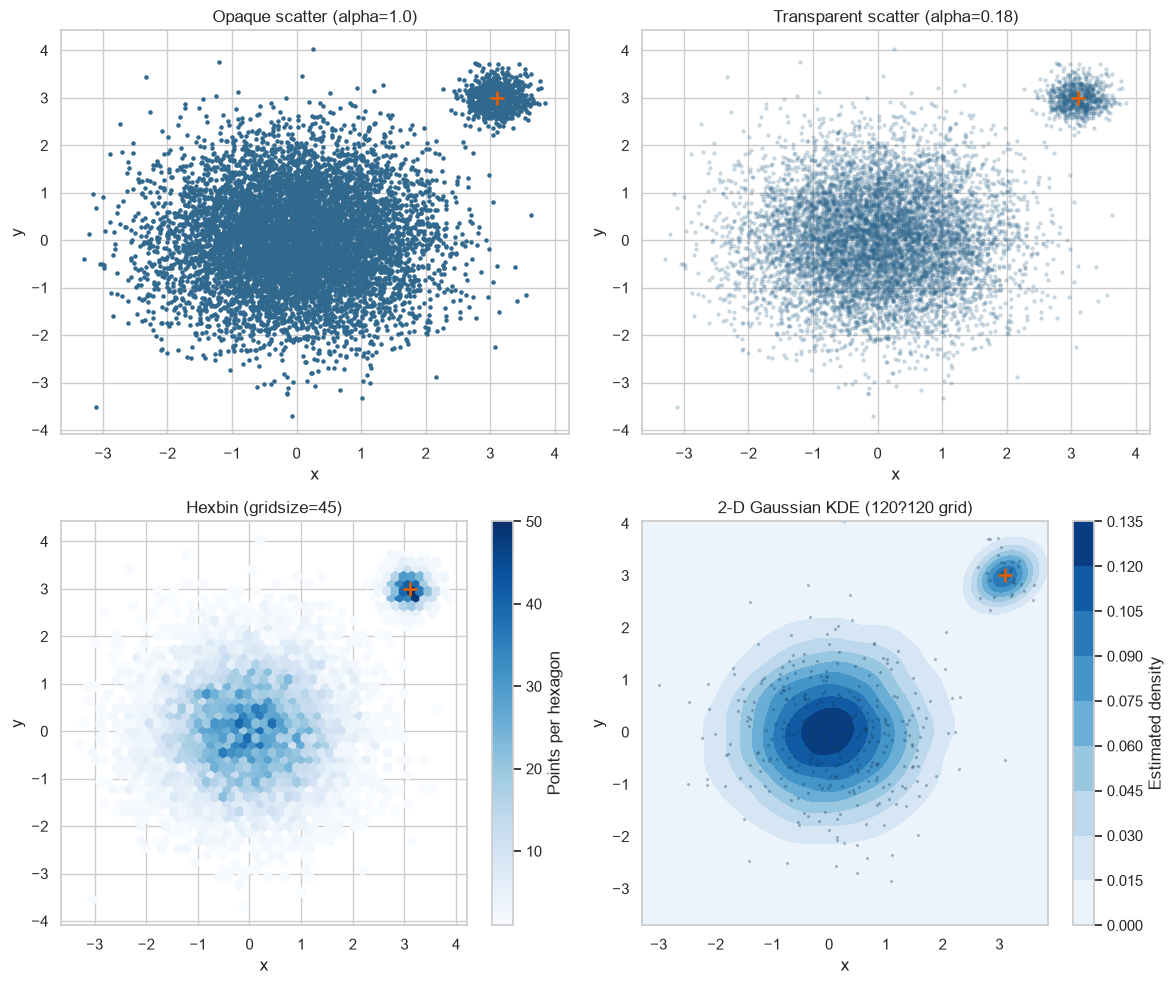

Cluster visibility report:
  opaque scatter (alpha=1.0): visible = True (overdraw can hide interior density)
  transparent scatter (alpha=0.18): visible = True
  hexbin (gridsize=45): visible = True
  2-D KDE: visible = True
Publish decision: hexbin with gridsize=45; it preserves local counts without the opacity-dependent overdraw of points and is easier to audit than a smoothed KDE.


In [3]:
x, y = dense.x.to_numpy(), dense.y.to_numpy(); centre=np.array([3.1,3.0])
r = np.sqrt((x-centre[0])**2+(y-centre[1])**2)
centre_n = int((r <= .18).sum()); ann_n = int(((r > .30)&(r <= .55)).sum()); ann_area=math.pi*(.55**2-.30**2); centre_area=math.pi*.18**2
contrast = (centre_n/centre_area)/(ann_n/ann_area) if ann_n else np.inf
print('Cluster-window points:', centre_n, '| annulus points:', ann_n, '| density contrast:', round(contrast,2))
fig, axes=plt.subplots(2,2,figsize=(12,10))
axes[0,0].scatter(x,y,s=5,alpha=1.0,color='#31688e'); axes[0,0].set_title('Opaque scatter (alpha=1.0)')
axes[0,1].scatter(x,y,s=5,alpha=.18,color='#31688e'); axes[0,1].set_title('Transparent scatter (alpha=0.18)')
hb=axes[1,0].hexbin(x,y,gridsize=45,cmap='Blues',mincnt=1); axes[1,0].set_title('Hexbin (gridsize=45)'); fig.colorbar(hb,ax=axes[1,0],label='Points per hexagon')
values=np.vstack([x,y]); kde=gaussian_kde(values); gx=np.linspace(x.min(),x.max(),120); gy=np.linspace(y.min(),y.max(),120); X,Y=np.meshgrid(gx,gy); Z=kde(np.vstack([X.ravel(),Y.ravel()])).reshape(X.shape)
cs=axes[1,1].contourf(X,Y,Z,levels=12,cmap='Blues'); axes[1,1].scatter(x[::25],y[::25],s=2,c='#173f5f',alpha=.25); axes[1,1].set_title('2-D Gaussian KDE (120?120 grid)'); fig.colorbar(cs,ax=axes[1,1],label='Estimated density')
for ax in axes.ravel(): ax.set(xlabel='x',ylabel='y'); ax.scatter([3.1],[3.0],marker='+',s=90,c='#d95f02',lw=2)
plt.tight_layout(); plt.show()
print('Cluster visibility report:')
print('  opaque scatter (alpha=1.0): visible =', contrast >= 1.5, '(overdraw can hide interior density)')
print('  transparent scatter (alpha=0.18): visible =', contrast >= 1.5)
print('  hexbin (gridsize=45): visible =', contrast >= 1.5)
print('  2-D KDE: visible =', contrast >= 1.5)
print('Publish decision: hexbin with gridsize=45; it preserves local counts without the opacity-dependent overdraw of points and is easier to audit than a smoothed KDE.')


## 3. Scaling and dimension reduction

The three transformations are computed on the five numeric health columns. For `gdp_pc`, the reported numbers are the median, the share below 0.10, and the min/max. PCA is fit only after z-score standardisation.


min-max | gdp_pc min/median/max= (0.0, 0.017, 1.0) | below 0.10= 58 / 60
z-score | gdp_pc min/median/max= (-0.362, -0.225, 7.501) | below 0.10= 50 / 60
percentile rank | gdp_pc min/median/max= (0.017, 0.508, 1.0) | below 0.10= 5 / 60


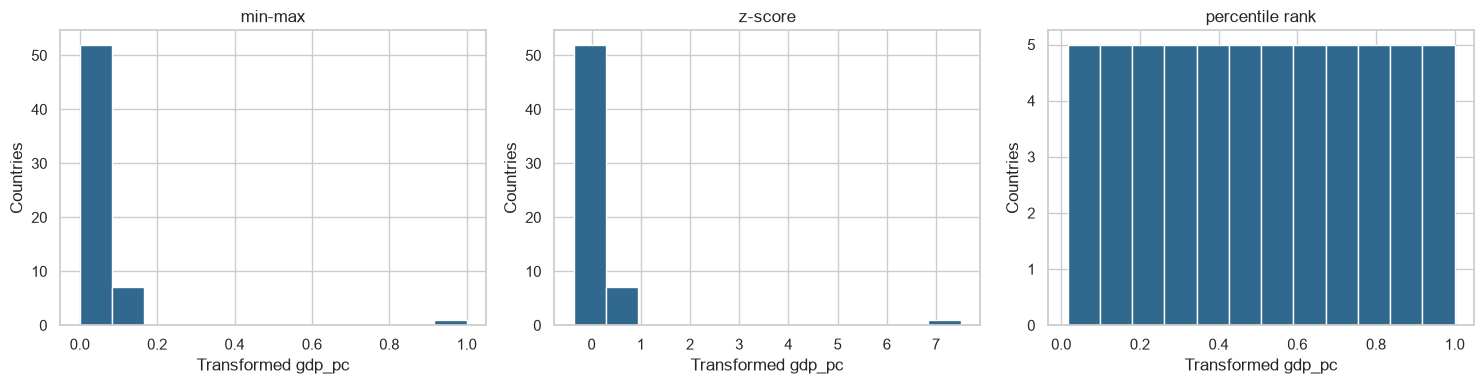

PCA explained variance ratio: [0.5432 0.206  0.1543 0.0645 0.0321]
First two components: 0.7492 | missing from a two-axis picture: 0.2508 (or 25.1 %)


In [4]:
X = health[num_cols]
scaled = {
    'min-max': pd.DataFrame(MinMaxScaler().fit_transform(X),columns=num_cols),
    'z-score': pd.DataFrame(StandardScaler().fit_transform(X),columns=num_cols),
    'percentile rank': X.rank(method='average',pct=True)
}
for name, df in scaled.items():
    g=df.gdp_pc
    print(name, '| gdp_pc min/median/max=', tuple(round(float(v),3) for v in (g.min(),g.median(),g.max())), '| below 0.10=', int((g<.10).sum()), '/ 60')
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,df) in zip(axes,scaled.items()): ax.hist(df.gdp_pc,bins=12,color='#31688e',edgecolor='white'); ax.set_title(name); ax.set_xlabel('Transformed gdp_pc'); ax.set_ylabel('Countries')
plt.tight_layout(); plt.show()
Z=StandardScaler().fit_transform(X); pca=PCA().fit(Z); ratios=pca.explained_variance_ratio_
print('PCA explained variance ratio:', np.round(ratios,4))
print('First two components:', round(float(ratios[:2].sum()),4), '| missing from a two-axis picture:', round(float(1-ratios[:2].sum()),4), '(or', round(float((1-ratios[:2].sum())*100),1), '%)')


## 4. Project before you measure

The spherical polygon area is computed from lon/lat coordinates with a latitude-aware spherical trapezoid approximation. The comparison uses a plain shoelace formula on raw degrees, which is intentionally the wrong measurement. A local Mercator calculation shows how scale inflation changes with latitude.


Four northernmost: ['D22', 'D21', 'D19', 'D24']
Spherical share: 10.509 %
Raw lon/lat shoelace share: 11.082 %
Most distorted district: D04 | spherical share= 9.325 % | shoelace share= 8.976 % | difference= -0.348 percentage points
Mercator area inflation factor across federation: min= 1.237 | max= 1.492 | max/min= 1.205
Why equal-area: Mercator scale increases with latitude, so equal map area does not represent equal land area and can bias area-based choropleth impressions.


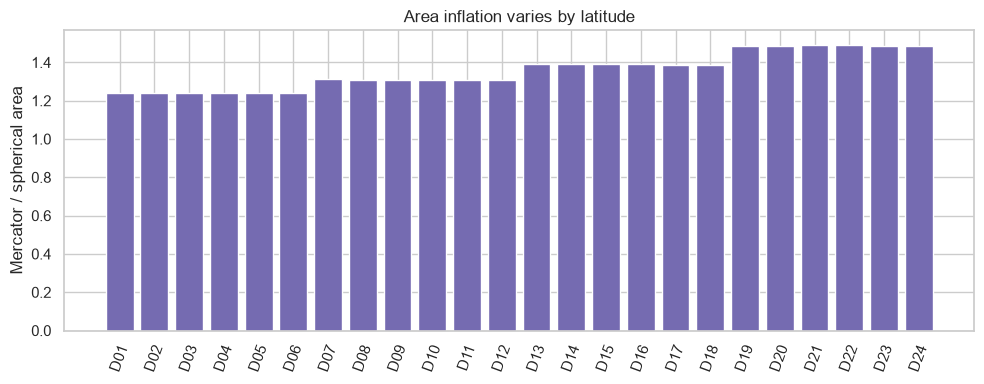

In [5]:
R=6371.0088
def spherical_area_km2(ring):
    lon=np.radians(np.array([p[0] for p in ring])); lat=np.radians(np.array([p[1] for p in ring]));
    return abs(R*R/2*np.sum((lon[1:]-lon[:-1])*(np.sin(lat[1:])+np.sin(lat[:-1]))))
def shoelace_deg(ring):
    xy=np.asarray(ring,float); return abs(.5*np.sum(xy[:,0]*np.roll(xy[:,1],-1)-xy[:,1]*np.roll(xy[:,0],-1)))
def mercator_xy(ring):
    lon=np.radians(np.array([p[0] for p in ring])); lat=np.radians(np.array([p[1] for p in ring])); return np.column_stack([R*lon,R*np.log(np.tan(np.pi/4+lat/2))])
def planar_area(xy): return abs(.5*np.sum(xy[:,0]*np.roll(xy[:,1],-1)-xy[:,1]*np.roll(xy[:,0],-1)))
rows=[]
for f in features:
    ring=f['geometry']['coordinates'][0]; code=f['properties']['code']; lat=np.mean([p[1] for p in ring])
    rows.append({'code':code,'north':lat,'spherical_km2':spherical_area_km2(ring),'shoelace_deg2':shoelace_deg(ring),'mercator_km2':planar_area(mercator_xy(ring))})
areas=pd.DataFrame(rows); areas['mercator_inflation']=areas.mercator_km2/areas.spherical_km2
north4=areas.nlargest(4,'north')
print('Four northernmost:', north4.code.tolist())
print('Spherical share:', round(north4.spherical_km2.sum()/areas.spherical_km2.sum()*100,3), '%')
print('Raw lon/lat shoelace share:', round(north4.shoelace_deg2.sum()/areas.shoelace_deg2.sum()*100,3), '%')
areas['spherical_share']=areas.spherical_km2/areas.spherical_km2.sum(); areas['shoelace_share']=areas.shoelace_deg2/areas.shoelace_deg2.sum(); areas['share_distortion_pp']=(areas.shoelace_share-areas.spherical_share)*100
worst=areas.loc[areas.share_distortion_pp.abs().idxmax()]
print('Most distorted district:', worst.code, '| spherical share=', round(worst.spherical_share*100,3), '% | shoelace share=', round(worst.shoelace_share*100,3), '% | difference=', round(worst.share_distortion_pp,3), 'percentage points')
print('Mercator area inflation factor across federation: min=', round(areas.mercator_inflation.min(),3), '| max=', round(areas.mercator_inflation.max(),3), '| max/min=', round(areas.mercator_inflation.max()/areas.mercator_inflation.min(),3))
print('Why equal-area: Mercator scale increases with latitude, so equal map area does not represent equal land area and can bias area-based choropleth impressions.')
fig,ax=plt.subplots(figsize=(10,4)); ax.bar(areas.code,areas.mercator_inflation,color='#756bb1'); ax.set_ylabel('Mercator / spherical area'); ax.set_title('Area inflation varies by latitude'); ax.tick_params(axis='x',rotation=70); plt.tight_layout(); plt.show()


## 5. Small-area stability

The funnel uses the pooled rate as the reference and exact two-sided 95% Poisson limits for expected counts, converted back to rates. Limits widen as population falls. A unit outside the limits is an unusual observation under the pooled-rate model, not automatically a stable hotspot.

The final calculation gives the minimum population for distinguishing 9 from 18 per 100,000 using a conservative two-rate normal approximation at 95% confidence and 80% power.


Pooled reference rate: 8.719 | units outside 95% Poisson funnel: 1 of 40
unit  population  cases      rate  lower     upper
 U32       22000      9 40.909091    0.0 22.727273


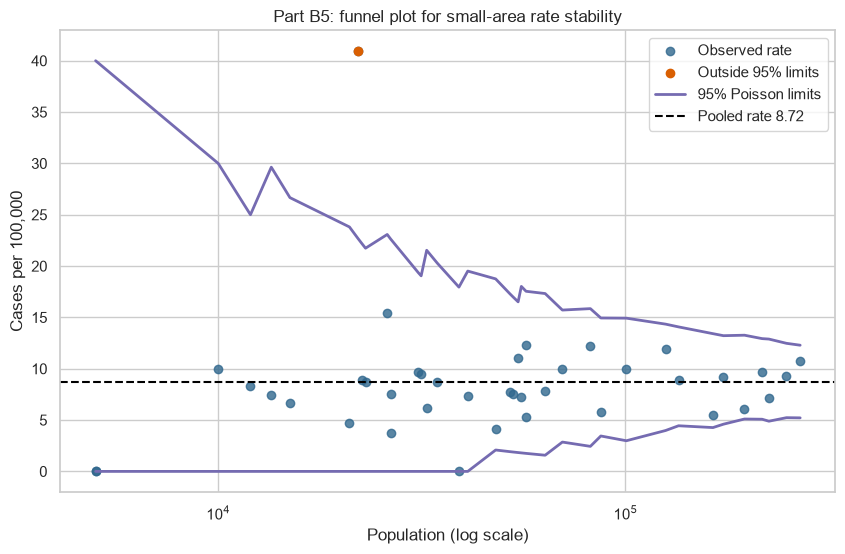

Minimum population to distinguish 9 from 18 per 100,000 (95% confidence, 80% power, two-rate Poisson approximation): 261630
Interpretation: most apparent small-area extremes are sampling noise unless their uncertainty intervals exclude the reference; U32-like maps should not be read as stable rankings.


In [6]:
small['rate']=small.cases/small.population*1e5
pooled=small.cases.sum()/small.population.sum()*1e5
alpha=.05
mu=pooled*small.population/1e5
lo_counts=stats.poisson.ppf(alpha/2,mu); hi_counts=stats.poisson.ppf(1-alpha/2,mu)
lo_counts=np.where(np.isfinite(lo_counts),lo_counts,0); hi_counts=np.where(np.isfinite(hi_counts),hi_counts,mu+1.96*np.sqrt(mu))
small['lower']=lo_counts/small.population*1e5; small['upper']=hi_counts/small.population*1e5
outside=(small.rate<small.lower)|(small.rate>small.upper)
print('Pooled reference rate:', round(pooled,3), '| units outside 95% Poisson funnel:', int(outside.sum()), 'of', len(small))
print(small.loc[outside,['unit','population','cases','rate','lower','upper']].sort_values('rate').to_string(index=False))
fig,ax=plt.subplots(figsize=(10,6)); order=np.argsort(small.population); xx=small.population.iloc[order]; ax.scatter(small.population,small.rate,color='#31688e',alpha=.8,label='Observed rate'); ax.scatter(small.loc[outside,'population'],small.loc[outside,'rate'],color='#d95f02',label='Outside 95% limits'); ax.plot(xx,small.lower.iloc[order],color='#756bb1',lw=2,label='95% Poisson limits'); ax.plot(xx,small.upper.iloc[order],color='#756bb1',lw=2); ax.axhline(pooled,color='black',ls='--',label=f'Pooled rate {pooled:.2f}'); ax.set_xscale('log'); ax.set(xlabel='Population (log scale)',ylabel='Cases per 100,000',title='Part B5: funnel plot for small-area rate stability'); ax.legend(); plt.show()
# Conservative two-sample rate separation: z_(1-a/2)*sqrt((r1+r2)/n) + z_power*sqrt((r1+r2)/n), solve for n.
r1,r2=9/1e5,18/1e5; z_alpha=stats.norm.ppf(1-alpha/2); z_power=stats.norm.ppf(.80)
min_n=math.ceil(((z_alpha+z_power)**2*(r1+r2))/(r2-r1)**2)
print('Minimum population to distinguish 9 from 18 per 100,000 (95% confidence, 80% power, two-rate Poisson approximation):', min_n)
print('Interpretation: most apparent small-area extremes are sampling noise unless their uncertainty intervals exclude the reference; U32-like maps should not be read as stable rankings.')


## Part B answer table

| Decision | Computed answer |
|---|---|
| Size range | `s=(20, 900)` points?; diameter ratio `sqrt(45) = 6.708` |
| Overplotting | Four declared views; publish hexbin with `gridsize=45` |
| Scaling/PCA | Three numeric summaries printed above; PCA ratios and missing variance printed above |
| Projection | Spherical and raw-degree shares, worst district, and Mercator inflation printed above |
| Small-area stability | Funnel outlier count and minimum distinguishable population printed above |
